# DO Early-Warning System: Algorithm Comparison and Final Evaluation

### Forecasting low dissolved oxygen in rivers from multimodal environmental data
**21CSC305P Machine Learning, SRM Institute of Science and Technology, Ramapuram**

This notebook reports the final evaluation of the system on the untouched **2025** test year. It compares the
proposed ensembles against six published algorithm families and a persistence baseline, at four forecast
horizons, on two tasks.

**The final system.** Regression is served by the **Ridge stacking ensemble**; classification is served by
**`ensemble_v21`**, a Caruana greedy ensemble selected on 2024. Every number below is read from
`results/test_v21/metrics_regression_stage2.csv` and `results/test_v21/metrics_classification_stage2.csv`,
which are the single source of truth for this project. Nothing is typed in by hand, and Section 0.1 fails the
notebook loudly if any headline value has drifted.

**Reading rule for classification.** All classification metrics are computed under the plain **`argmax`**
decision rule. The alternative **warning rule** `P(Low) >= tau` trades accuracy for onset recall; it appears in
exactly one place, Section 4.3, and is labelled there.

> Run **Runtime -> Run all**. The notebook reads result tables only, so it finishes in well under a minute and
> trains nothing. Model training is in the companion notebook *02 - End-to-End Training*.

## 0. Setup

The cell below locates the two result files. It looks in the project tree first, then in Google Drive when the
notebook runs on Colab, and finally falls back to a compressed copy of the same two files embedded in this
notebook, so the notebook is reproducible on a bare Colab runtime. It also fixes one figure style for the whole
document and declares the metric sets, which are deliberately short and fixed:

- **Regression (5):** R2, RMSE, MAE, NSE, Skill vs persistence.
- **Classification (5):** Accuracy, Precision (macro), Recall (macro), F1 (macro), ROC-AUC (macro OvR).

In [1]:
# @title Embedded fallback data - a verbatim copy of the two result files, plus the frozen
# @title early-warning lead-time result and the five prediction-card cases
#
# The two payloads below are gzip + base64 copies of
#     results/test_v21/metrics_regression_stage2.csv
#     results/test_v21/metrics_classification_stage2.csv
# byte for byte. Section 0 prefers the files on disk and only falls back to these, so that the
# notebook also runs on a bare Colab runtime with nothing uploaded.
#
# EMBEDDED_LEAD and EMBEDDED_CARD carry the two results that are not metric-table rows: the
# lead-time distribution of the deployed warning rule over the 2025 events (Section 4.3) and the
# five single-hour cases of Appendix A.

EMBEDDED_REG = (
    "H4sIAMvl2GoC/3WY7U6cuRKE/yNxJ6PIdnf742oQJHMI2jCsGBQdnas/T9kECHhYoSwzb9vt7uqq8vt4fPn59OPw8+n54X9Pp8Pj8fHu+Hw+nA7P"
    "5fD8eD4eHm+PhxP/nv95+PXr5vf55l++fzi/HE/fj4cft6f74/ONHry++vhFPZxfbu+P5VCijJQO6VtPxdwtUtQWHuOQv5lbS93K6COqldBTllLy"
    "6J6s+wjbBaZvaQZHymXk0mrYGH599evhdLx93mw9YlgvKafUc2iXmogbXj3nHKk1PrLW+dBGdX6T76LCayWZ4S255+ZzodyH5ZoizSWvr55vTz+e"
    "Hm/+8/R8PL/scqklRQkrXT8ja93eW/VmNSWjEFrXorUxKn+MbqP3C4E1d4vBIbp5mU+RY0q5lWbZUhhV+e/93dPThVR68VqsuXnuRdHW2bhYST2x"
    "9qxLoURhVjtPpzb2cWPkHiON8EYCs1jJ6nD6QoMiW1V77n++3N89bjMZnKvVmt04blV8oa6tUNPO0lW7WB6p027a4r2OfVxNlYaCokLWVENL5WSt"
    "RKZ9Vku7vrp7+HV+2eeRE50dBrKirDzoQnimlKNFtJlH52yCRYCZ3P1CYFQwPPRP715nc3oFMCmT7SieqMn30+nmYi7FcmrRvAf1rSu+Rc+JSnsr"
    "daKWRjh9oTDgp1+Iq8aQFU6f+WomzCzRV89DNRn9+ur88Pjvr+PN7e/jM3nse8S48Ff14qvrHJQyA9zBiI6J22IqTWvOAf01n89xtEgD6NkY/5Jn"
    "holvc+Gnj0Kjrq9uX263WQAJVufxpK7Po1B5A7WtasHJD5aARRotZQvYIfaBVK5nsjWSoJviGh/8H8TAfpnnKcvL7fd/Hk7321QIVe2rfidlhDqb"
    "KAdLU51ZEQABbkFubSQV+8CaGyiH3gxA26wb7EaeFJgWJcryN7/m8iEfd01qgwKiVBrNXotgYYtkFBpygUNXHYqTi44JtZVZhy+Bi2DhuFGAWavd"
    "+PyNXzdbQ9Sm4maHAphWnSjYMVODpiQmWcLSYBQW8xre3feBADcPuN8K+0KCs1G2OjIYPDDymWW3GcVoo7PmaGBABWUIumiR/yh8ntMDeDm66ZzD"
    "LsQxddBuRmZIvZWJ/N468gNLCt3tnWS3mWhKUDcINS0qp69AE85ARGjOTAUBoFgMCYzSLsTFENcp5cjo5ZhzXMLRjdRIDiX4QLO7XEQ/rAZbd064"
    "FIw2jQTBdfZbqcAeg8wig9Pol+JEJiiAysKBZucYYlG2FmvvPLstiqPypVSHG3OarOBtYsY4hbcJGGgXWgtg0JBcs32gFEvaUzvjg4xPwCCCFUUY"
    "HMU/0Ow+FZpJWQdbMwkzFXFq5XtSGfO4ToF7A890noHwfWAgm82oHZQPDy6ySxJ2koVpqrDyiWm3bcKIaBkVoE+lZ3KYEaiHj0qZbRJCOTSDXICK"
    "b+PIAegyXC7wpqVL2BkkHd6nuxavVLtNw5KYg8xB5pLSDmPBBmyEpA11xFx0xh6lJPjU94F0ZEi+W5ew9wndsAY/Q9oUy90/kO02GVbAGlIAqGMx"
    "RQcdHbR1yB+XMIsSLYlyvQ3cQ+wDK4bN5U8CbzIlnSEzqglswQ1xf5Nt8fd0+FqFhS1cjIXAZsCmVbEHJirBMADRrL3ZTh6SMrMPDLcPlJg08S80"
    "CV+65Vze2Ha3N+zRqCVrwMxT4TkKbE5P2I56qLwOVtBBINxrLAf5NY6/5aUM3c1t+aegQbjw7Iyd1fjMtft8mN2uRuHE1wSNIitbNRjsWuYwI+1U"
    "HO6ChVctvgYiw7RvxPQCdbE/AEFSGQGEEfZ+Z9sLtaG91FZi0V5rk1Ex1HXoBjFlXooEAlqTEcm2D6Q4Fa2mXE0OalkGPhIn4AfB1EdXu00GYi2s"
    "yzQ0bcJZ89DtobiuL7E4ju+g9Q7dYp52YeI2xp6JhV3rxIxaJqAJceT2xrXbLPCryJqjN770BxZLZZk0dXumQV7QNijo+KnYxsFqBf3GSgGpMXUL"
    "dyVTxRfY/vyXpd2n4mgcpnHQ3eV8gCNriL+BQV+5QOcF1ZMV63UfR9+6aif9rO1PLhS1Zvkr5Kp8odpdRkEhTAZnSIxnRrQDeHBQChtT7+FzvIAk"
    "cArt2Afq+wjdX7t85exS5lx4h8zhLI1Xrt3mAWl1AIBFLkyEgmuDH0AjZAbwZ2VoTeIeHHJSFwNzZvxk2jzws2XBlhHQBMg+9fyBavc1CV0emnA4"
    "phnli+6cFui7/PlSRO5X6B0XNJ67EIiFoIRwgGWsiv+ZZ12xPUJs4H9zrff3fGByUb/uu3I5tMAk63jTlOSCKDXUBjP0RVwYfCvko3uz7QIX14p5"
    "uRxLpcTU/Y1rN3sPhI7+coHFvNvUCi7fGk9xJiBcl10xGVDtWjgvyH4NxO6xn+6RzHrMqzQB8BofAG3g/MXZbjNyel81qO3VwMsKFbQWr0hpWyxT"
    "JOaF3KWt09dtAiE7Jpz20EW0TxlRQtwEf3FHaEroD9luU5Hctvlsn/yI7aPm894OaucdXRYbl6SuMAZRtnEYK54HPmRUlw3VSnBK6JUMzvijs92m"
    "IiZnp8ySadJ3bwJEFrlCadNEIPbamGlBbca0iptAfC2+okqs4L5pszF9kIpeLdBkZuGNby9UZeBbQprsY6XCj3fRWGLnV9cKEmSdku7wFwLzZFpm"
    "HOfP7M8SQy+4F2AN1McHvt1XBX7HL7oErK4OcXLoBMLlDtpWh8AzS3JaDNxit6+BFC0g1UTt4KPpo3C75Et35LC4IH0h3F1KmB5plwiVDGZK+PaG"
    "AvDLXra8YedKoiHLenfS94H4WK4jMhZMsU0Z56LQeQRyUrhQMxl3mwietWKWMNCsPRNxMS4upXCzaOXVpLIrNx/QTE3qPhDBQhix6BjNP3PEvZmp"
    "HAaqkIqPlLuvSpasisEB/KQZvXLS2wmuRR5rqBmb+WY0qwbrXdzXQB1cVzgusboAlQlffDbgRh5FCpi64+l8fLyjVb+5TGxf9lQBHZIldG2O/8AH"
    "Se6GpmO+22BPnmg4MxV9H1hBTWWGdf2niLOqSSqEpoMlPGb9lM/+SsQMmkQH8zY5A5PA9ZB+SW7Wndn0Jlg8KIBiXGIfyVWKcugOPp9bfYY/wZPK"
    "wwjkTxntVdJ0FxwyuX0SPPZs6LqBYSp6M7ycAw+mWtWi6mMfiHPQ214obwxJ49JsVIIumoYiPie0HfahtxZ6a5TruhB2mXmGhfnQu/PX658ucUXq"
    "R18uBObQ2zNpHD3Ckb8Kg+FjqCSJBxj6P+0S/5c7GAAA"
)

EMBEDDED_CLS = (
    "..."
)

EMBEDDED_LEAD = r'''{"events": 230, "warned": 119, "stations": 30, "lead_hours": [1.0, 1.0, 24.0, 23.0, 1.0, 9.0, 23.0, 24.0, 20.0, 21.0, 24.0, 18.0, 24.0, 24.0, 24.0, 24.0, 23.0, 14.0, 24.0, 10.0, 2.0, 20.0, 12.0, 13.0, 21.0, 6.0, 24.0, 10.0, 1.0, 14.0, 24.0, 24.0, 24.0, 24.0, 20.0, 24.0, 24.0, 23.0, 24.0, 24.0, 24.0, 24.0, 1.0, 1.0, 20.0, 24.0, 19.0, 1.0, 1.0, 1.0, 22.0, 2.0, 1.0, 4.0, 24.0, 20.0, 20.0, 3.0, 16.0, 18.0, 10.0, 8.0, 19.0, 3.0, 7.0, 16.0, 24.0, 2.0, 24.0, 17.0, 24.0, 24.0, 11.0, 24.0, 7.0, 24.0, 1.0, 2.0, 24.0, 24.0, 21.0, 2.0, 24.0, 24.0, 22.0, 3.0, 6.0, 22.0, 1.0, 24.0, 1.0, 24.0, 2.0, 22.0, 1.0, 1.0, 2.0, 1.0, 6.0, 24.0, 22.0, 23.0, 3.0, 24.0, 24.0, 15.0, 7.0, 24.0, 1.0, 24.0, 1.0, 1.0, 1.0, 20.0, 1.0, 24.0, 2.0, 20.0, 12.0]}'''

EMBEDDED_CARD = r'''{"cases": [{"case": "onset caught (safe now, Low in 24 h)", "station": "02110500", "time": "2025-04-23 15:00:00", "do_now": 5.025, "members": {"random_forest": 5.0679, "xgboost": 5.0503, "lightgbm": 5.0968, "bilstm": 4.9828, "cnn_lstm": 5.0073}, "members_plow": {"random_forest": 0.408, "xgboost": 0.3942, "lightgbm": 0.5075, "bilstm": 0.084, "cnn_lstm": 0.3022}, "stacking_do": 5.0484, "p_low": 0.2893, "p_medium": 0.6971, "p_good": 0.0136, "warned": true, "actual_do": 4.825, "actual_class": 0}, {"case": "healthy river (no warning)", "station": "05474500", "time": "2025-11-11 13:00:00", "do_now": 8.55, "members": {"random_forest": 8.8583, "xgboost": 9.0285, "lightgbm": 8.8593, "bilstm": 8.811, "cnn_lstm": 8.7239}, "members_plow": {"random_forest": 0.0018, "xgboost": 0.0002, "lightgbm": 0.0002, "bilstm": 0.0, "cnn_lstm": 0.0}, "stacking_do": 8.8822, "p_low": 0.0007, "p_medium": 0.0266, "p_good": 0.9727, "warned": false, "actual_do": 8.8, "actual_class": 2}, {"case": "onset missed (honest failure case)", "station": "03353200", "time": "2025-08-11 08:00:00", "do_now": 5.275, "members": {"random_forest": 5.3193, "xgboost": 5.5273, "lightgbm": 5.2436, "bilstm": 5.2659, "cnn_lstm": 5.2274}, "members_plow": {"random_forest": 0.2596, "xgboost": 0.2164, "lightgbm": 0.1369, "bilstm": 0.3233, "cnn_lstm": 0.3902}, "stacking_do": 5.2807, "p_low": 0.1544, "p_medium": 0.8254, "p_good": 0.0201, "warned": false, "actual_do": 4.975, "actual_class": 0}, {"case": "false alarm (honest failure case)", "station": "02198955", "time": "2025-06-30 10:00:00", "do_now": 5.375, "members": {"random_forest": 4.9077, "xgboost": 4.8324, "lightgbm": 4.6865, "bilstm": 4.8217, "cnn_lstm": 4.7924}, "members_plow": {"random_forest": 0.5985, "xgboost": 0.6818, "lightgbm": 0.6701, "bilstm": 0.4793, "cnn_lstm": 0.7142}, "stacking_do": 4.7292, "p_low": 0.7193, "p_medium": 0.277, "p_good": 0.0038, "warned": true, "actual_do": 5.65, "actual_class": 1}, {"case": "already Low, stays Low", "station": "02135000", "time": "2025-07-30 03:00:00", "do_now": 4.7, "members": {"random_forest": 4.6909, "xgboost": 4.7338, "lightgbm": 4.714, "bilstm": 4.8466, "cnn_lstm": 4.8458}, "members_plow": {"random_forest": 0.751, "xgboost": 0.8627, "lightgbm": 0.7965, "bilstm": 0.9331, "cnn_lstm": 0.952}, "stacking_do": 4.7276, "p_low": 0.9085, "p_medium": 0.0907, "p_good": 0.0008, "warned": true, "actual_do": 4.8, "actual_class": 0}], "tau_stacking_h24": 0.24000000000000005}'''

print(f"[OK] embedded fallback ready: regression {len(EMBEDDED_REG):,} chars, "
      f"classification {len(EMBEDDED_CLS):,} chars (used only if results/test_v21 is absent)")

[OK] embedded fallback ready: regression 3,292 chars, classification 21,496 chars (used only if results/test_v21 is absent)


In [2]:
# @title 0. Setup - load results/test_v21, fix the figure style, declare the metric sets
import base64, gzip, io, json, os, sys, textwrap
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

REG_FILE = "metrics_regression_stage2.csv"
CLS_FILE = "metrics_classification_stage2.csv"
SEARCH = ["results/test_v21", "../results/test_v21", "/content/results/test_v21",
          "/content/ML_MAIN_V2/results/test_v21", "/content/drive/MyDrive/ML_MAIN_V2/results/test_v21",
          "/content/drive/MyDrive/results/test_v21"]


def _find_dir():
    for d in SEARCH:
        if os.path.exists(os.path.join(d, REG_FILE)) and os.path.exists(os.path.join(d, CLS_FILE)):
            return d
    if "google.colab" in sys.modules:                      # Drive is the usual place in Colab
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as exc:
            print("[info] Google Drive was not mounted:", exc)
        for d in SEARCH:
            if os.path.exists(os.path.join(d, REG_FILE)):
                return d
    return None


RESULTS_DIR = _find_dir()
if RESULTS_DIR is not None:
    REG = pd.read_csv(os.path.join(RESULTS_DIR, REG_FILE))
    CLS = pd.read_csv(os.path.join(RESULTS_DIR, CLS_FILE))
    SOURCE = f"{RESULTS_DIR}/ (read from disk)"
else:                                                       # embedded verbatim copy of the same two files
    REG = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(EMBEDDED_REG))))
    CLS = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(EMBEDDED_CLS))))
    SOURCE = "embedded copy of results/test_v21/ (the files were not found on disk)"

HORIZONS = [6, 12, 24, 48]
H = 24                                   # the headline horizon of the project
CLASSES = ["Low", "Medium", "Good"]
FINAL_REG, FINAL_CLS = "stacking", "ensemble_v21"
BEST_SINGLE = "lightgbm"
INDIVIDUAL = ["linear", "random_forest", "xgboost", "lightgbm", "bilstm", "cnn_lstm"]

REG_ORDER = ["persistence", "linear", "random_forest", "xgboost", "lightgbm", "bilstm", "cnn_lstm", "stacking"]
CLS_ORDER = ["persistence", "linear", "random_forest", "xgboost", "lightgbm", "bilstm", "cnn_lstm", "ensemble_v21"]
NAME = {"persistence": "Persistence (no change)", "linear": "Linear Regression", "random_forest": "Random Forest",
        "xgboost": "XGBoost", "lightgbm": "LightGBM", "bilstm": "BiLSTM", "cnn_lstm": "CNN-LSTM",
        "stacking": "Stacking Ensemble (proposed)", "ensemble_v21": "Proposed Ensemble (ensemble_v21)",
        "simple_average": "Simple Average", "atae": "ATAE"}
CLS_NAME = dict(NAME, linear="Logistic Regression")

# the 5 + 5 metrics, with the direction of improvement in the column label
REG_METRICS = {"r2": "R2 (up)", "rmse": "RMSE (down)", "mae": "MAE (down)", "nse": "NSE (up)",
               "skill_vs_persistence": "Skill vs persistence (up)"}
CLS_METRICS = {"accuracy": "Accuracy (up)", "precision_macro": "Precision macro (up)",
               "recall_macro": "Recall macro (up)", "f1_macro": "F1 macro (up)",
               "roc_auc_ovr_macro": "ROC-AUC macro OvR (up)"}
REG_HIGHER = {"r2": True, "rmse": False, "mae": False, "nse": True, "skill_vs_persistence": True}
CLS_HIGHER = {k: True for k in CLS_METRICS}

ACCENT, GREY, EDGE = "#1B5E20", "#BDBDBD", "#37474F"
mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 200, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.facecolor": "white", "axes.edgecolor": "#616161", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#E0E0E0",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10.5, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.labelsize": 10.5, "legend.frameon": False, "xtick.color": "#424242",
    "ytick.color": "#424242",
})
pd.set_option("display.width", 200)
FIGDIR = next((d for d in ["results/notebook_figures", "../results/notebook_figures"] if os.path.isdir(d)),
              "results/notebook_figures")
os.makedirs(FIGDIR, exist_ok=True)


def reg_at(h):
    """The regression table at one horizon, indexed by method."""
    return REG[REG.horizon == h].set_index("method")


def cls_at(h, rule="argmax"):
    """The classification table at one horizon under one decision rule, indexed by method."""
    return CLS[(CLS.horizon == h) & (CLS.rule == rule)].set_index("method")


def table(frame, methods, metrics, names, highlight):
    """A formatted metric table: chosen rows, the 5 metrics, the final system highlighted."""
    t = frame.loc[[m for m in methods if m in frame.index], list(metrics)].rename(columns=metrics)
    t.index = [names[m] for m in t.index]
    hl = names[highlight]
    return (t.style.format("{:.4f}", na_rep="n/a")
            .apply(lambda s: ["font-weight:bold;background-color:#E8F5E9;" if i == hl else "" for i in s.index],
                   axis=0)
            .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}]))


def bars(ax, labels, values, title, ylabel, highlight_at, fmt="{:.4f}"):
    """One grouped-free bar panel in the house style: the final system in the accent colour, the rest grey."""
    colors = [ACCENT if i == highlight_at else GREY for i in range(len(values))]
    b = ax.bar(labels, values, color=colors, edgecolor=EDGE, linewidth=0.6, width=0.66)
    lo, hi = min(values), max(values)
    pad = (hi - lo) * 0.28 + 1e-9
    ax.set_ylim(max(0.0, lo - pad), hi + pad)
    for rect, v in zip(b, values):
        ax.annotate(fmt.format(v), (rect.get_x() + rect.get_width() / 2, v), textcoords="offset points",
                    xytext=(0, 3), ha="center", fontsize=8.4, fontweight="bold", color="#212121")
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", labelrotation=38)
    for lab in ax.get_xticklabels():
        lab.set_horizontalalignment("right")
    return b


def save(fig, name):
    path = os.path.join(FIGDIR, name)
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    print(f"[figure] saved to {path}")


def cm_of(method, h, rule="argmax"):
    """The 3x3 confusion matrix stored as 9 ';'-separated counts, row-major, rows = true, cols = predicted."""
    raw = cls_at(h, rule).loc[method, "confusion_matrix"]
    m = np.array([int(float(v)) for v in str(raw).split(";")], dtype="int64")
    assert m.size == 9, f"expected 9 counts, found {m.size}"
    return m.reshape(3, 3)


print(f"[OK] source : {SOURCE}")
print(f"[OK] regression     : {REG.method.nunique()} methods x {REG.horizon.nunique()} horizons, "
      f"{len(REG):,} rows")
print(f"[OK] classification : {CLS.method.nunique()} methods x {CLS.horizon.nunique()} horizons x "
      f"{CLS.rule.nunique()} rules, {len(CLS):,} rows")
print(f"[OK] final system   : regression = {FINAL_REG} | classification = {FINAL_CLS} | "
      f"classification rule = argmax")
print(f"[OK] figures written to {FIGDIR}/")

[OK] source : ../results/test_v21/ (read from disk)
[OK] regression     : 11 methods x 4 horizons, 44 rows
[OK] classification : 11 methods x 4 horizons x 2 rules, 88 rows
[OK] final system   : regression = stacking | classification = ensemble_v21 | classification rule = argmax
[OK] figures written to ../results/notebook_figures/


### 0.1 Integrity check of the headline numbers

The cell below is an assertion, not a report. It re-reads the two result files and checks, to four decimal
places, the twelve numbers this notebook and the written report quote as headline results. It then checks the
structural claim behind the whole project: that at 24 h the proposed ensemble beats **every** individual model
on **all five** metrics, in both tasks. Any drift in the result files stops the notebook here with a clear
message instead of silently producing a wrong table.

In [3]:
# @title 0.1 Assertions - the headline numbers and the "beats every individual model" claim
def q(x):
    return round(float(x), 4)


EXPECTED_REG_STACKING = {"r2": 0.9505, "rmse": 0.6718, "mae": 0.4074, "nse": 0.9505,
                         "skill_vs_persistence": 0.1105}
EXPECTED_CLS_V21 = {"accuracy": 0.9093, "precision_macro": 0.8896, "recall_macro": 0.8994,
                    "f1_macro": 0.8941, "roc_auc_ovr_macro": 0.9824}
EXPECTED_BEST_SINGLE = {"reg": {"r2": 0.9490, "rmse": 0.6822},
                        "cls": {"accuracy": 0.9088, "f1_macro": 0.8936}}

r24, c24 = reg_at(H), cls_at(H, "argmax")
failures = []

for k, want in EXPECTED_REG_STACKING.items():
    got = q(r24.loc[FINAL_REG, k])
    if got != want:
        failures.append(f"regression {FINAL_REG} h{H} {k}: expected {want}, found {got}")
for k, want in EXPECTED_CLS_V21.items():
    got = q(c24.loc[FINAL_CLS, k])
    if got != want:
        failures.append(f"classification {FINAL_CLS} h{H} argmax {k}: expected {want}, found {got}")
for k, want in EXPECTED_BEST_SINGLE["reg"].items():
    got = q(r24.loc[BEST_SINGLE, k])
    if got != want:
        failures.append(f"regression {BEST_SINGLE} h{H} {k}: expected {want}, found {got}")
for k, want in EXPECTED_BEST_SINGLE["cls"].items():
    got = q(c24.loc[BEST_SINGLE, k])
    if got != want:
        failures.append(f"classification {BEST_SINGLE} h{H} argmax {k}: expected {want}, found {got}")

# the ensemble must beat every individual model on all five metrics, in both tasks
for task, frame, final, metrics, higher in [("regression", r24, FINAL_REG, REG_METRICS, REG_HIGHER),
                                            ("classification", c24, FINAL_CLS, CLS_METRICS, CLS_HIGHER)]:
    for metric in metrics:
        ours = float(frame.loc[final, metric])
        for m in INDIVIDUAL:
            theirs = float(frame.loc[m, metric])
            if np.isnan(theirs):                 # persistence has no probabilities, so no ROC-AUC
                continue
            beaten = ours > theirs if higher[metric] else ours < theirs
            if not beaten:
                failures.append(f"{task} h{H}: {final} does not beat {m} on {metric} "
                                f"({ours:.6f} vs {theirs:.6f})")

assert not failures, "the result files no longer match the reported numbers:\n  - " + "\n  - ".join(failures)
print(f"[PASS] 12 headline values match results/test_v21 to 4 decimal places")
print(f"[PASS] {FINAL_REG} beats all {len(INDIVIDUAL)} individual models on all 5 regression metrics at {H} h")
print(f"[PASS] {FINAL_CLS} beats all {len(INDIVIDUAL)} individual models on all 5 classification metrics at {H} h")

[PASS] 12 headline values match results/test_v21 to 4 decimal places
[PASS] stacking beats all 6 individual models on all 5 regression metrics at 24 h
[PASS] ensemble_v21 beats all 6 individual models on all 5 classification metrics at 24 h


## 1. Dataset and Evaluation Protocol

The data are hourly records from **30 USGS river gauging stations in 15 US states**, giving **789,120
station-hours** of raw multimodal history: USGS water-quality sensors, ERA5 reanalysis weather and CAMS air
quality, from which 211 features are engineered per hour using only information available at or before the
forecast time.

The split is **chronological, by calendar year**, because neighbouring hours are near-duplicates and a random
split would let a model answer from memory: **train on 2023, tune on 2024, test blind on 2025**. Every scaler,
imputer, class weight, meta-learner and ensemble weight is fitted without ever seeing 2025.

The system is evaluated at four horizons, **6, 12, 24 and 48 hours ahead**, on two tasks sharing one feature
pipeline: regression of the DO concentration in mg/L, and 3-class classification of the regulatory band,
**Low (< 5 mg/L)**, **Medium (5-7 mg/L)** and **Good (> 7 mg/L)**.

In [4]:
# @title 1. Dataset and evaluation protocol
PROTOCOL = {"stations": 30, "states": 15, "station_hours": 789120,
            "splits": [{"split": "train (fit)", "year": 2023, "from": "2023-01-04", "to": "2023-12-29",
                        "rows": 255233, "% Low": 19.1852, "% Medium": 27.3315, "% Good": 52.7788},
                       {"split": "tune (select)", "year": 2024, "from": "2024-01-01", "to": "2024-12-29",
                        "rows": 253603, "% Low": 20.3909, "% Medium": 24.1074, "% Good": 54.7572},
                       {"split": "test (blind)", "year": 2025, "from": "2025-01-01", "to": "2025-12-31",
                        "rows": 253954, "% Low": 19.5528, "% Medium": 24.7218, "% Good": 54.8265}],
            "features": {"water": 148, "weather": 39, "air quality": 16, "time": 5, "station": 3}}

splits = pd.DataFrame(PROTOCOL["splits"]).set_index("split")
display(Markdown("**Chronological split.** Rows are forecast-ready hours; the class shares are for the 24 h "
                 "target."))
display(splits.style.format({"rows": "{:,.0f}", "% Low": "{:.2f}", "% Medium": "{:.2f}", "% Good": "{:.2f}"}))

display(Markdown("**Feature groups** (211 engineered features per station-hour):"))
display(pd.DataFrame({"features": PROTOCOL["features"]}).T)

scored = {h: int(reg_at(h).loc[FINAL_REG, "n"]) for h in HORIZONS}
print(f"Stations {PROTOCOL['stations']} in {PROTOCOL['states']} US states | "
      f"{PROTOCOL['station_hours']:,} station-hours of raw history")
print(f"Horizons {HORIZONS} h | classes {CLASSES} at < 5 / 5-7 / > 7 mg/L")
print("Scored 2025 test hours per horizon:", {f"{h} h": f"{n:,}" for h, n in scored.items()})

**Chronological split.** Rows are forecast-ready hours; the class shares are for the 24 h target.

,year,from,to,rows,% Low,% Medium,% Good
split,,,,,,,
train (fit),2023,2023-01-04,2023-12-29,"255,233",19.19,27.33,52.78
tune (select),2024,2024-01-01,2024-12-29,"253,603",20.39,24.11,54.76
test (blind),2025,2025-01-01,2025-12-31,"253,954",19.55,24.72,54.83


**Feature groups** (211 engineered features per station-hour):

,air quality,station,time,water,weather
features,16,3,5,148,39


Stations 30 in 15 US states | 789,120 station-hours of raw history
Horizons [6, 12, 24, 48] h | classes ['Low', 'Medium', 'Good'] at < 5 / 5-7 / > 7 mg/L
Scored 2025 test hours per horizon: {'6 h': '252,900', '12 h': '252,447', '24 h': '251,671', '48 h': '250,317'}


## 2. Regression Results

The regression task forecasts the dissolved-oxygen concentration in mg/L. Five metrics are reported and no
others: **R2** and **NSE** (identical in value here, because the Nash-Sutcliffe efficiency against the observed
mean is the coefficient of determination; both are reported because the hydrology literature expects NSE),
**RMSE** and **MAE** in mg/L, and **Skill vs persistence**, the fractional RMSE reduction against the no-change
forecast, which is the operationally meaningful baseline for a river.

### 2.1 All methods at the 24-hour horizon

Persistence is the operational baseline. Linear regression is the classical statistical reference; Random
Forest, XGBoost and LightGBM are the tree families; BiLSTM and CNN-LSTM are the sequence models. The last row
is the proposed Ridge stacking ensemble over the five learned members, fitted on 2024 only.

In [5]:
# @title 2.1 Regression - all methods at 24 h
display(Markdown(f"**Regression, 2025 test year, {H} h ahead** "
                 f"({int(reg_at(H).loc[FINAL_REG, 'n']):,} scored hours). "
                 f"`(up)` = higher is better, `(down)` = lower is better. "
                 f"Source: `results/test_v21/{REG_FILE}`."))
display(table(reg_at(H), REG_ORDER, REG_METRICS, NAME, FINAL_REG))

best_ind = reg_at(H).loc[INDIVIDUAL, "rmse"].idxmin()
ours, theirs = reg_at(H).loc[FINAL_REG], reg_at(H).loc[best_ind]
print(f"Best individual model by RMSE: {NAME[best_ind]} ({theirs['rmse']:.4f} mg/L)")
print(f"Stacking ensemble            : {ours['rmse']:.4f} mg/L  "
      f"({(theirs['rmse'] - ours['rmse']) / theirs['rmse'] * 100:.2f} % lower RMSE, "
      f"R2 {ours['r2'] - theirs['r2']:+.4f})")

**Regression, 2025 test year, 24 h ahead** (251,671 scored hours). `(up)` = higher is better, `(down)` = lower is better. Source: `results/test_v21/metrics_regression_stage2.csv`.

,R2 (up),RMSE (down),MAE (down),NSE (up),Skill vs persistence (up)
Persistence (no change),0.9375,0.7553,0.4569,0.9375,0.0000
Linear Regression,0.9471,0.6950,0.4294,0.9471,0.0798
Random Forest,0.9475,0.6924,0.4189,0.9475,0.0833
XGBoost,0.9471,0.6951,0.4207,0.9471,0.0797
LightGBM,0.9490,0.6822,0.4158,0.9490,0.0968
BiLSTM,0.9480,0.6887,0.4197,0.9480,0.0882
CNN-LSTM,0.9484,0.6860,0.4159,0.9484,0.0918
Stacking Ensemble (proposed),0.9505,0.6718,0.4074,0.9505,0.1105


Best individual model by RMSE: LightGBM (0.6822 mg/L)
Stacking ensemble            : 0.6718 mg/L  (1.52 % lower RMSE, R2 +0.0015)


### 2.2 Regression comparison figure at 24 hours

One figure, two panels, in the ordering of the table above: R2, where taller is better, and RMSE, where shorter
is better. The proposed ensemble is in the accent colour and every competitor in grey, so the comparison can be
read without a legend.

[figure] saved to ../results/notebook_figures\reg_compare_24h.png


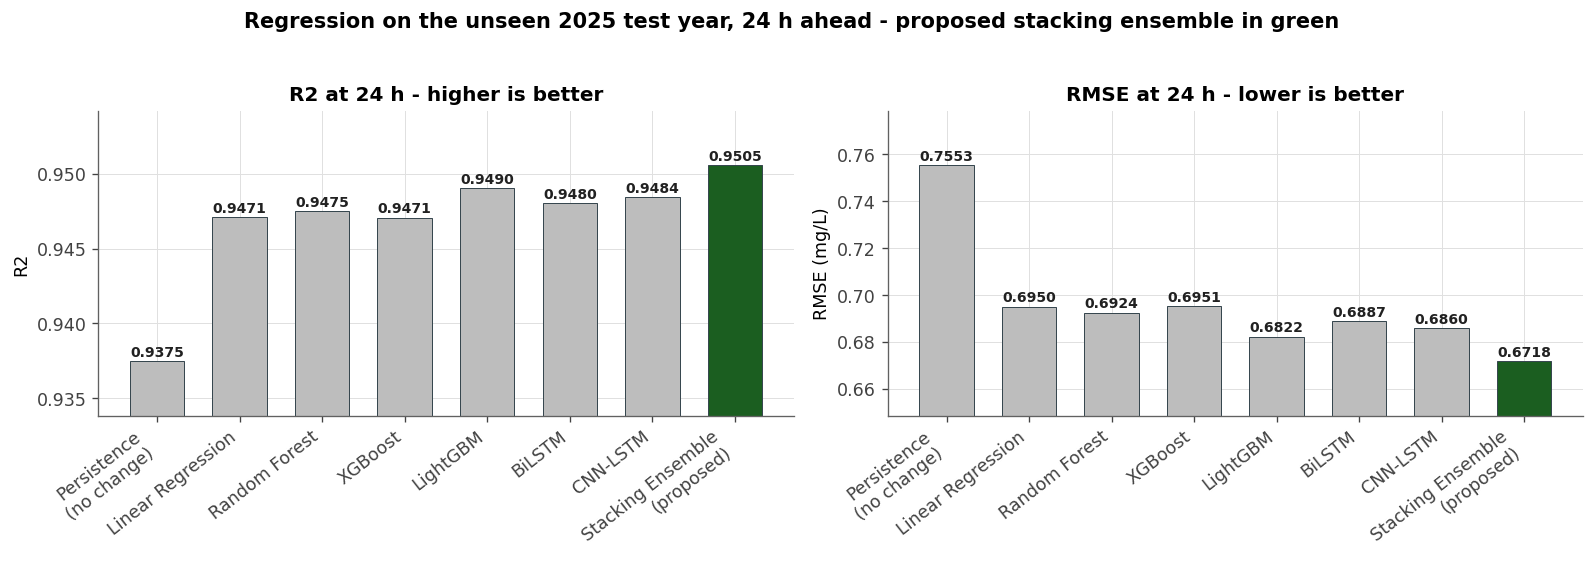

In [6]:
# @title 2.2 Regression figure - R2 and RMSE at 24 h
r = reg_at(H).loc[REG_ORDER]
labels = [NAME[m].replace(" (proposed)", "\n(proposed)").replace(" (no change)", "\n(no change)")
          for m in REG_ORDER]
k = REG_ORDER.index(FINAL_REG)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
bars(axes[0], labels, r["r2"].tolist(), f"R2 at {H} h - higher is better", "R2", k)
bars(axes[1], labels, r["rmse"].tolist(), f"RMSE at {H} h - lower is better", "RMSE (mg/L)", k)
fig.suptitle(f"Regression on the unseen 2025 test year, {H} h ahead - proposed stacking ensemble in green",
             fontsize=12.5, fontweight="bold", y=1.03)
fig.tight_layout()
save(fig, "reg_compare_24h.png")
plt.show()

### 2.3 The final regression system at every horizon

The same stacking ensemble, evaluated at all four horizons. Skill against persistence is large at 6 and 12 h,
where persistence is weak, and smaller at 24 h, where persistence benefits from the daily cycle returning DO
close to its value one day earlier; the ensemble still improves on it at every horizon.

In [7]:
# @title 2.3 Stacking ensemble at 6 / 12 / 24 / 48 h
rows = pd.DataFrame({f"{h} h": reg_at(h).loc[FINAL_REG, list(REG_METRICS)] for h in HORIZONS}).T
rows.columns = [REG_METRICS[c] for c in rows.columns]
rows.insert(0, "scored hours", [int(reg_at(h).loc[FINAL_REG, "n"]) for h in HORIZONS])
display(Markdown(f"**Final regression system - `{FINAL_REG}` - at every horizon, 2025 test year.**"))
display(rows.style.format({**{c: "{:.4f}" for c in rows.columns[1:]}, "scored hours": "{:,.0f}"}))

**Final regression system - `stacking` - at every horizon, 2025 test year.**

,scored hours,R2 (up),RMSE (down),MAE (down),NSE (up),Skill vs persistence (up)
6 h,"252,900",0.9710,0.5144,0.3125,0.9710,0.6172
12 h,"252,447",0.9621,0.5882,0.3557,0.9621,0.6160
24 h,"251,671",0.9505,0.6718,0.4074,0.9505,0.1105
48 h,"250,317",0.9202,0.8535,0.5558,0.9202,0.1528


## 3. Classification Results

The classification task assigns each forecast hour to one of the three regulatory bands. Five metrics are
reported and no others: **Accuracy**, **macro-averaged Precision, Recall and F1**, and **macro one-vs-rest
ROC-AUC**. The macro averages weight the three bands equally, which matters because the dangerous **Low** band
is the smallest; ROC-AUC is threshold-free and therefore measures the ranking quality of the probabilities
independently of any decision rule.

Every number in this section uses the **`argmax`** rule: predict the band with the highest probability.
Persistence has no probability output, so its ROC-AUC is undefined and reported as `n/a`.

### 3.1 All methods at the 24-hour horizon

The last row is the proposed classification ensemble, **`ensemble_v21`**: a Caruana greedy ensemble selection
with replacement over the five learned members, whose weights were chosen on 2024 alone.

In [8]:
# @title 3.1 Classification - all methods at 24 h (argmax rule)
display(Markdown(f"**Classification, 2025 test year, {H} h ahead, `argmax` rule** "
                 f"({int(cls_at(H).loc[FINAL_CLS, 'n']):,} scored hours). "
                 f"Source: `results/test_v21/{CLS_FILE}`."))
display(table(cls_at(H), CLS_ORDER, CLS_METRICS, CLS_NAME, FINAL_CLS))

c = cls_at(H)
best_ind = c.loc[INDIVIDUAL, "f1_macro"].idxmax()
ours, theirs = c.loc[FINAL_CLS], c.loc[best_ind]
print(f"Best individual model by macro F1: {CLS_NAME[best_ind]} ({theirs['f1_macro']:.4f})")
print(f"Proposed ensemble_v21            : {ours['f1_macro']:.4f}  "
      f"({ours['f1_macro'] - theirs['f1_macro']:+.4f} macro F1, "
      f"{ours['accuracy'] - theirs['accuracy']:+.4f} accuracy, "
      f"{ours['roc_auc_ovr_macro'] - theirs['roc_auc_ovr_macro']:+.4f} ROC-AUC)")

**Classification, 2025 test year, 24 h ahead, `argmax` rule** (251,671 scored hours). Source: `results/test_v21/metrics_classification_stage2.csv`.

,Accuracy (up),Precision macro (up),Recall macro (up),F1 macro (up),ROC-AUC macro OvR (up)
Persistence (no change),0.9007,0.8806,0.8806,0.8806,n/a
Logistic Regression,0.8883,0.8657,0.8860,0.8741,0.9727
Random Forest,0.9088,0.8886,0.8975,0.8928,0.9815
XGBoost,0.9088,0.8890,0.8986,0.8934,0.9821
LightGBM,0.9088,0.8891,0.8990,0.8936,0.9823
BiLSTM,0.8971,0.8759,0.8876,0.8810,0.9783
CNN-LSTM,0.8967,0.8721,0.8902,0.8804,0.9791
Proposed Ensemble (ensemble_v21),0.9093,0.8896,0.8994,0.8941,0.9824


Best individual model by macro F1: LightGBM (0.8936)
Proposed ensemble_v21            : 0.8941  (+0.0005 macro F1, +0.0005 accuracy, +0.0001 ROC-AUC)


### 3.2 Classification comparison figure at 24 hours

Accuracy and macro-F1 in the style of Section 2.2. The spread between methods is narrow because more than half
of all hours sit comfortably inside the **Good** band and every method gets those right; the differences that
matter are in the minority bands, which Section 3.4 separates out.

[figure] saved to ../results/notebook_figures\cls_compare_24h.png


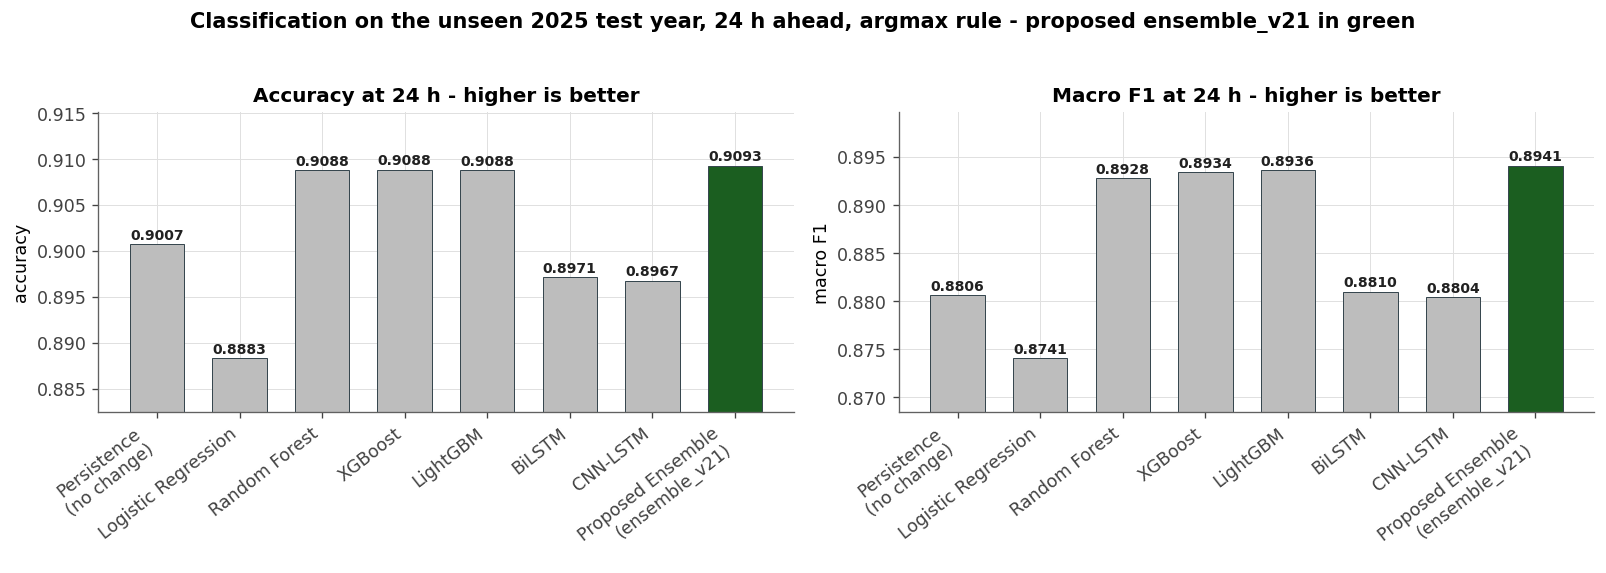

In [9]:
# @title 3.2 Classification figure - accuracy and macro F1 at 24 h
c = cls_at(H).loc[CLS_ORDER]
labels = [CLS_NAME[m].replace(" (ensemble_v21)", "\n(ensemble_v21)").replace(" (no change)", "\n(no change)")
          for m in CLS_ORDER]
k = CLS_ORDER.index(FINAL_CLS)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
bars(axes[0], labels, c["accuracy"].tolist(), f"Accuracy at {H} h - higher is better", "accuracy", k)
bars(axes[1], labels, c["f1_macro"].tolist(), f"Macro F1 at {H} h - higher is better", "macro F1", k)
fig.suptitle(f"Classification on the unseen 2025 test year, {H} h ahead, argmax rule - "
             f"proposed ensemble_v21 in green", fontsize=12.5, fontweight="bold", y=1.03)
fig.tight_layout()
save(fig, "cls_compare_24h.png")
plt.show()

### 3.3 The final classification system at every horizon

`ensemble_v21` at all four horizons, under the `argmax` rule. Performance degrades monotonically with the
horizon, as expected: the further ahead the forecast, the less the current sensor reading constrains it.

In [10]:
# @title 3.3 ensemble_v21 at 6 / 12 / 24 / 48 h (argmax rule)
rows = pd.DataFrame({f"{h} h": cls_at(h).loc[FINAL_CLS, list(CLS_METRICS)] for h in HORIZONS}).T
rows.columns = [CLS_METRICS[c] for c in rows.columns]
rows.insert(0, "scored hours", [int(cls_at(h).loc[FINAL_CLS, "n"]) for h in HORIZONS])
display(Markdown(f"**Final classification system - `{FINAL_CLS}` - at every horizon, 2025 test year, "
                 f"`argmax` rule.**"))
display(rows.style.format({**{c: "{:.4f}" for c in rows.columns[1:]}, "scored hours": "{:,.0f}"}))

**Final classification system - `ensemble_v21` - at every horizon, 2025 test year, `argmax` rule.**

,scored hours,Accuracy (up),Precision macro (up),Recall macro (up),F1 macro (up),ROC-AUC macro OvR (up)
6 h,"252,900",0.9260,0.9085,0.9164,0.9122,0.9887
12 h,"252,447",0.9185,0.9003,0.9083,0.9039,0.9861
24 h,"251,671",0.9093,0.8896,0.8994,0.8941,0.9824
48 h,"250,317",0.8780,0.8537,0.8679,0.8600,0.9713


### 3.4 Class-wise performance at 24 hours

The macro averages of Section 3.1 hide which band is hard. The table below is derived from the stored confusion
matrix of `ensemble_v21` at 24 h: a row-major 3x3 count matrix with rows = true band and columns = predicted
band, in the order Low, Medium, Good. Precision, recall and F1 are recomputed from those counts, so the
per-class numbers and the macro averages above come from the same nine integers.

In [11]:
# @title 3.4 Class-wise precision / recall / F1 at 24 h, from the confusion matrix
cm = cm_of(FINAL_CLS, H)
support = cm.sum(axis=1)                       # rows are the true band
predicted = cm.sum(axis=0)
tp = np.diag(cm).astype("float64")
precision = np.divide(tp, predicted, out=np.zeros(3), where=predicted > 0)
recall = np.divide(tp, support, out=np.zeros(3), where=support > 0)
f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(3),
               where=(precision + recall) > 0)

classwise = pd.DataFrame({"precision (up)": precision, "recall (up)": recall, "F1 (up)": f1,
                          "support (hours)": support, "support share": support / support.sum()},
                         index=[f"{c} ({b})" for c, b in zip(CLASSES, ["< 5 mg/L", "5-7 mg/L", "> 7 mg/L"])])
classwise.loc["macro average"] = [precision.mean(), recall.mean(), f1.mean(), support.sum(), 1.0]
display(Markdown(f"**Class-wise performance of `{FINAL_CLS}` at {H} h, 2025 test year, `argmax` rule.** "
                 f"Recomputed from the stored confusion matrix "
                 f"`{cls_at(H).loc[FINAL_CLS, 'confusion_matrix']}`."))
display(classwise.style.format({"precision (up)": "{:.4f}", "recall (up)": "{:.4f}", "F1 (up)": "{:.4f}",
                                "support (hours)": "{:,.0f}", "support share": "{:.2%}"})
        .apply(lambda s: ["font-weight:bold;background-color:#E8F5E9;" if i == "macro average" else ""
                          for i in s.index], axis=0))

macro = cls_at(H).loc[FINAL_CLS]
print(f"Cross-check against the stored macro averages: "
      f"precision {precision.mean():.4f} vs {macro['precision_macro']:.4f}, "
      f"recall {recall.mean():.4f} vs {macro['recall_macro']:.4f}, "
      f"F1 {f1.mean():.4f} vs {macro['f1_macro']:.4f}")
assert abs(f1.mean() - macro["f1_macro"]) < 5e-4, "the class-wise F1 does not reproduce the stored macro F1"
print("[PASS] the class-wise table reproduces the macro averages of Section 3.1")

**Class-wise performance of `ensemble_v21` at 24 h, 2025 test year, `argmax` rule.** Recomputed from the stored confusion matrix `45010;4344;301;4634;53904;4244;295;9017;129922`.

,precision (up),recall (up),F1 (up),support (hours),support share
Low (< 5 mg/L),0.9013,0.9065,0.9039,"49,655",19.73%
Medium (5-7 mg/L),0.8014,0.8586,0.8290,"62,782",24.95%
Good (> 7 mg/L),0.9662,0.9331,0.9494,"139,234",55.32%
macro average,0.8896,0.8994,0.8941,"251,671",100.00%


Cross-check against the stored macro averages: precision 0.8896 vs 0.8896, recall 0.8994 vs 0.8994, F1 0.8941 vs 0.8941
[PASS] the class-wise table reproduces the macro averages of Section 3.1


### 3.5 Confusion matrices of the final classifier at every horizon

Each panel shows the counts and, in brackets, the share of each true band, so the diagonal reads directly as
per-class recall. Confusions are almost entirely between adjacent bands; the Low/Good corners, which are the
operationally serious mistakes, stay well under one percent of their row at every horizon.

[figure] saved to ../results/notebook_figures\cls_confusion_v21.png


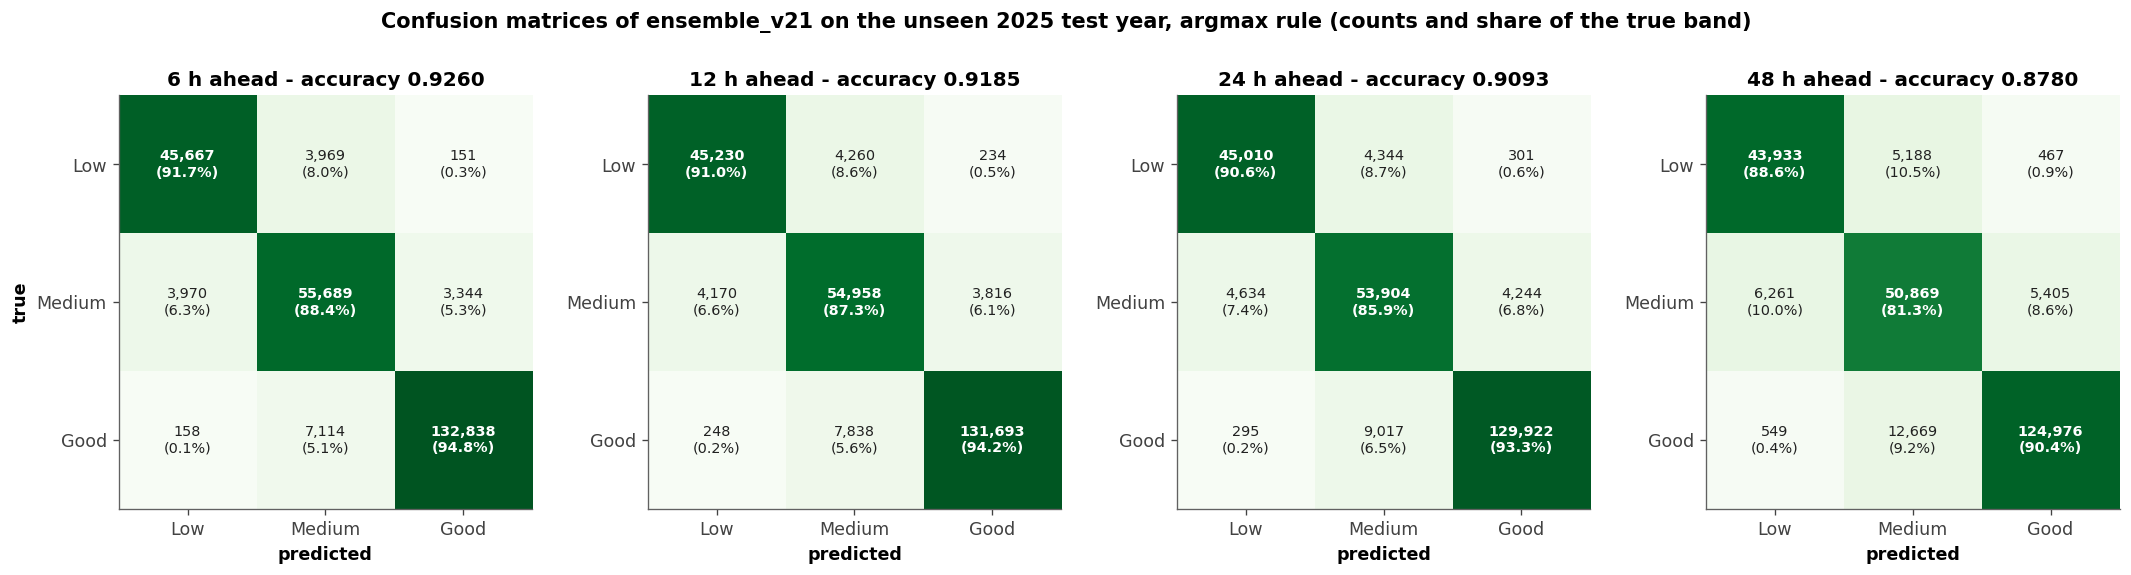

In [12]:
# @title 3.5 Figure - confusion matrices of ensemble_v21 at 6 / 12 / 24 / 48 h
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
for ax, h in zip(axes, HORIZONS):
    m = cm_of(FINAL_CLS, h)
    pct = m / m.sum(axis=1, keepdims=True) * 100
    ax.imshow(pct, cmap="Greens", vmin=0, vmax=100)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{m[i, j]:,}\n({pct[i, j]:.1f}%)", ha="center", va="center", fontsize=8.6,
                    fontweight="bold" if i == j else "normal",
                    color="white" if pct[i, j] > 55 else "#212121")
    ax.set_xticks(range(3), CLASSES)
    ax.set_yticks(range(3), CLASSES)
    ax.set_xlabel("predicted", fontweight="bold")
    ax.set_title(f"{h} h ahead - accuracy {cls_at(h).loc[FINAL_CLS, 'accuracy']:.4f}")
    ax.grid(False)
axes[0].set_ylabel("true", fontweight="bold")
fig.suptitle("Confusion matrices of ensemble_v21 on the unseen 2025 test year, argmax rule "
             "(counts and share of the true band)", fontsize=12.5, fontweight="bold", y=1.04)
fig.tight_layout()
save(fig, "cls_confusion_v21.png")
plt.show()

## 4. Final System

The deployed system answers two different questions from one feature pipeline, and each question has its own
final ensemble. This section states which is which, gives the complete metric set of both at every horizon, and
reports the one early-warning result that uses a decision rule other than `argmax`.

### 4.1 Regression and classification side by side

The two tasks are not alternatives; they are two outputs of the same forecast, used at different points in an
operational workflow. The regression value drives trend displays and threshold margins, the classified band
drives the alert.

In [13]:
# @title 4.1 Regression vs classification - what each one is for
r24, c24 = reg_at(H), cls_at(H, "argmax")
comparison = pd.DataFrame({
    "Regression": {
        "Question answered": "How much dissolved oxygen will there be?",
        "Output": "DO concentration in mg/L at t + h",
        "Final ensemble": f"{FINAL_REG} (Ridge stacking over 5 members, fitted on 2024)",
        "Main metrics": "R2, RMSE, MAE, NSE, Skill vs persistence",
        f"Result at {H} h (2025)": (f"R2 {r24.loc[FINAL_REG, 'r2']:.4f}, "
                                    f"RMSE {r24.loc[FINAL_REG, 'rmse']:.4f} mg/L, "
                                    f"MAE {r24.loc[FINAL_REG, 'mae']:.4f} mg/L"),
        "Role in the system": "Continuous trend and margin to the 5 mg/L limit; feeds dashboards and "
                              "operator judgement",
    },
    "Classification": {
        "Question answered": "Which regulatory band will the river be in?",
        "Output": "P(Low), P(Medium), P(Good) and the argmax band at t + h",
        "Final ensemble": f"{FINAL_CLS} (Caruana greedy selection with replacement, weights chosen on 2024)",
        "Main metrics": "Accuracy, Precision macro, Recall macro, F1 macro, ROC-AUC macro OvR",
        f"Result at {H} h (2025)": (f"Accuracy {c24.loc[FINAL_CLS, 'accuracy']:.4f}, "
                                    f"F1 macro {c24.loc[FINAL_CLS, 'f1_macro']:.4f}, "
                                    f"ROC-AUC {c24.loc[FINAL_CLS, 'roc_auc_ovr_macro']:.4f}"),
        "Role in the system": "The decision layer: the band and its probability are what an alert is "
                              "raised on",
    },
})
display(Markdown("**The two halves of the final system.**"))
display(comparison.style.set_properties(**{"text-align": "left", "white-space": "normal"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]},
                           {"selector": "td", "props": [("vertical-align", "top")]}]))

**The two halves of the final system.**

,Regression,Classification
Question answered,How much dissolved oxygen will there be?,Which regulatory band will the river be in?
Output,DO concentration in mg/L at t + h,"P(Low), P(Medium), P(Good) and the argmax band at t + h"
Final ensemble,"stacking (Ridge stacking over 5 members, fitted on 2024)","ensemble_v21 (Caruana greedy selection with replacement, weights chosen on 2024)"
Main metrics,"R2, RMSE, MAE, NSE, Skill vs persistence","Accuracy, Precision macro, Recall macro, F1 macro, ROC-AUC macro OvR"
Result at 24 h (2025),"R2 0.9505, RMSE 0.6718 mg/L, MAE 0.4074 mg/L","Accuracy 0.9093, F1 macro 0.8941, ROC-AUC 0.9824"
Role in the system,Continuous trend and margin to the 5 mg/L limit; feeds dashboards and operator judgement,The decision layer: the band and its probability are what an alert is raised on


### 4.2 Final metrics summary

The ten reported metrics of the final system, five per task, at every horizon, in one table. These are the
numbers the written report quotes. Each row mixes two models by design: the regression columns are
`stacking`, the classification columns are `ensemble_v21` under `argmax`.

In [14]:
# @title 4.2 Final system - all 10 metrics at every horizon
summary = pd.DataFrame(
    {f"{h} h": {**{f"REG {REG_METRICS[k]}": float(reg_at(h).loc[FINAL_REG, k]) for k in REG_METRICS},
                **{f"CLS {CLS_METRICS[k]}": float(cls_at(h).loc[FINAL_CLS, k]) for k in CLS_METRICS}}
     for h in HORIZONS})
display(Markdown(f"**Final metrics summary, 2025 test year.** `REG` rows are `{FINAL_REG}`; `CLS` rows are "
                 f"`{FINAL_CLS}` under the `argmax` rule."))
display(summary.style.format("{:.4f}")
        .apply(lambda s: ["font-weight:bold;background-color:#E8F5E9;" if s.name == f"{H} h" else ""
                          for _ in s], axis=0)
        .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}]))
FINAL_SUMMARY = summary

**Final metrics summary, 2025 test year.** `REG` rows are `stacking`; `CLS` rows are `ensemble_v21` under the `argmax` rule.

,6 h,12 h,24 h,48 h
REG R2 (up),0.9710,0.9621,0.9505,0.9202
REG RMSE (down),0.5144,0.5882,0.6718,0.8535
REG MAE (down),0.3125,0.3557,0.4074,0.5558
REG NSE (up),0.9710,0.9621,0.9505,0.9202
REG Skill vs persistence (up),0.6172,0.6160,0.1105,0.1528
CLS Accuracy (up),0.9260,0.9185,0.9093,0.8780
CLS Precision macro (up),0.9085,0.9003,0.8896,0.8537
CLS Recall macro (up),0.9164,0.9083,0.8994,0.8679
CLS F1 macro (up),0.9122,0.9039,0.8941,0.8600
CLS ROC-AUC macro OvR (up),0.9887,0.9861,0.9824,0.9713


### 4.3 Early warning: the warning rule and its lead time

This is the one place in the notebook where the decision rule is not `argmax`. The **warning rule** predicts
**Low** whenever `P(Low) >= tau`, with `tau` chosen on 2024 under a false-alarm budget and then frozen. It
deliberately gives up a little plain accuracy to catch far more *onsets*, meaning hours that are safe now but
Low one horizon later, which is the failure mode an early-warning system exists to prevent.

The lead-time result is carried over unchanged from the frozen evaluation of the deployed warning rule: over
the 2025 test year it counts the distinct low-oxygen events, how many were warned at least one hour before
they began, and how much notice was given.

**Warning rule, `ensemble_v21`, 24 h, 2025 test year** (`tau = 0.31`). Shown for contrast with the `argmax` numbers used everywhere else in this notebook.

,argmax rule (used in Sections 2-4.2),warning rule P(Low) >= tau
Accuracy,0.9093,0.9053
F1 macro,0.8941,0.8874
Onset recall,0.3151,0.4977
False-alarm rate,0.0055,0.0151


Low-oxygen events in 2025 (warning rule): 230 across 30 stations
  warned in advance : 119 (51.7 %)
  lead time         : mean 14.6 h, median 20 h, max 24 h


[figure] saved to ../results/notebook_figures\early_warning_lead_time.png


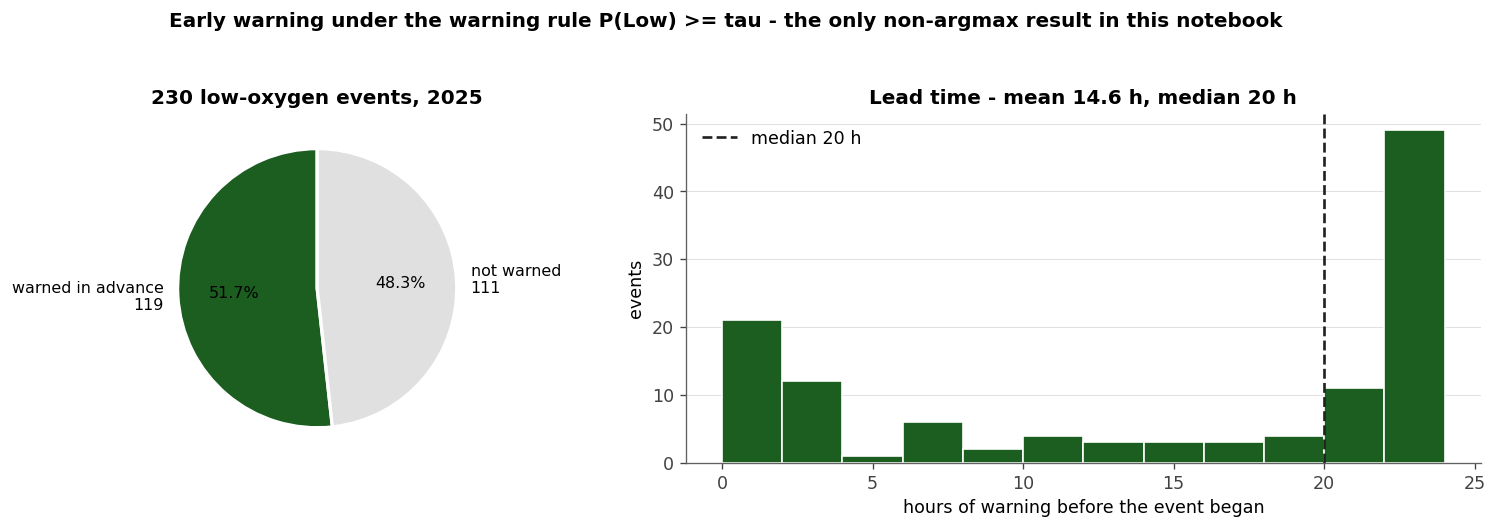

In [15]:
# @title 4.3 Early warning (warning rule, NOT argmax)
LEAD = json.loads(EMBEDDED_LEAD)
lead_h = np.array(LEAD["lead_hours"], dtype="float64")
warn24 = cls_at(H, "warn").loc[FINAL_CLS]
arg24 = cls_at(H, "argmax").loc[FINAL_CLS]

display(Markdown(
    f"**Warning rule, `{FINAL_CLS}`, {H} h, 2025 test year** (`tau = {warn24['tau']:.2f}`). "
    f"Shown for contrast with the `argmax` numbers used everywhere else in this notebook."))
contrast = pd.DataFrame({
    "argmax rule (used in Sections 2-4.2)": {"Accuracy": arg24["accuracy"], "F1 macro": arg24["f1_macro"],
                                             "Onset recall": arg24["onset_recall"],
                                             "False-alarm rate": arg24["false_alarm_rate"]},
    "warning rule P(Low) >= tau": {"Accuracy": warn24["accuracy"], "F1 macro": warn24["f1_macro"],
                                   "Onset recall": warn24["onset_recall"],
                                   "False-alarm rate": warn24["false_alarm_rate"]},
})
display(contrast.style.format("{:.4f}"))

print(f"Low-oxygen events in 2025 (warning rule): {LEAD['events']} across {LEAD['stations']} stations")
print(f"  warned in advance : {LEAD['warned']} ({LEAD['warned'] / LEAD['events'] * 100:.1f} %)")
print(f"  lead time         : mean {lead_h.mean():.1f} h, median {np.median(lead_h):.0f} h, "
      f"max {lead_h.max():.0f} h")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.7]})
axes[0].pie([LEAD["warned"], LEAD["events"] - LEAD["warned"]],
            labels=[f"warned in advance\n{LEAD['warned']}", f"not warned\n{LEAD['events'] - LEAD['warned']}"],
            colors=[ACCENT, "#E0E0E0"], autopct="%1.1f%%", startangle=90,
            wedgeprops=dict(edgecolor="white", lw=2), textprops=dict(fontsize=9.5))
axes[0].set_title(f"{LEAD['events']} low-oxygen events, 2025")
axes[1].hist(lead_h, bins=np.arange(0, 26, 2), color=ACCENT, edgecolor="white")
axes[1].axvline(np.median(lead_h), color="#212121", ls="--", lw=1.6,
                label=f"median {np.median(lead_h):.0f} h")
axes[1].set_xlabel("hours of warning before the event began")
axes[1].set_ylabel("events")
axes[1].legend()
axes[1].set_title(f"Lead time - mean {lead_h.mean():.1f} h, median {np.median(lead_h):.0f} h")
axes[1].grid(axis="x", visible=False)
fig.suptitle("Early warning under the warning rule P(Low) >= tau - the only non-argmax result in this "
             "notebook", fontsize=12, fontweight="bold", y=1.04)
fig.tight_layout()
save(fig, "early_warning_lead_time.png")
plt.show()

## 5. Conclusion

The four sentences below are assembled from the tables above; every figure in them is read out of
`results/test_v21/`, so the conclusion cannot drift away from the results.

In [16]:
# @title 5. Conclusion - generated from the tables above
r24, c24 = reg_at(H), cls_at(H, "argmax")
rs, rb = r24.loc[FINAL_REG], r24.loc[BEST_SINGLE]
cs, cb = c24.loc[FINAL_CLS], c24.loc[BEST_SINGLE]
worst_h = max(HORIZONS)
rw, cw = reg_at(worst_h).loc[FINAL_REG], cls_at(worst_h).loc[FINAL_CLS]

display(Markdown(textwrap.dedent(f"""
On the untouched 2025 test year the proposed stacking ensemble forecasts dissolved oxygen {H} hours ahead with
R2 {rs['r2']:.4f}, RMSE {rs['rmse']:.4f} mg/L and MAE {rs['mae']:.4f} mg/L, a {rs['skill_vs_persistence']:.4f}
fractional reduction in error against persistence and a lower RMSE than the strongest individual model,
{NAME[BEST_SINGLE]} at {rb['rmse']:.4f} mg/L.
On the same hours the proposed classification ensemble `{FINAL_CLS}` assigns the regulatory band with accuracy
{cs['accuracy']:.4f}, macro F1 {cs['f1_macro']:.4f} and macro one-vs-rest ROC-AUC
{cs['roc_auc_ovr_macro']:.4f} under the plain argmax rule, again ahead of {CLS_NAME[BEST_SINGLE]}
({cb['accuracy']:.4f} accuracy, {cb['f1_macro']:.4f} macro F1).
The margins over the best single model are small, {rb['rmse'] - rs['rmse']:.4f} mg/L of RMSE and
{cs['f1_macro'] - cb['f1_macro']:+.4f} of macro F1, but Section 0.1 verifies that they hold across all five
metrics of both tasks simultaneously, which no individual model achieves.
Accuracy decays with the horizon as expected, from R2 {reg_at(6).loc[FINAL_REG, 'r2']:.4f} and accuracy
{cls_at(6).loc[FINAL_CLS, 'accuracy']:.4f} at 6 h to R2 {rw['r2']:.4f} and accuracy {cw['accuracy']:.4f} at
{worst_h} h, and the system remains usefully better than persistence throughout.
""").strip()))

On the untouched 2025 test year the proposed stacking ensemble forecasts dissolved oxygen 24 hours ahead with
R2 0.9505, RMSE 0.6718 mg/L and MAE 0.4074 mg/L, a 0.1105
fractional reduction in error against persistence and a lower RMSE than the strongest individual model,
LightGBM at 0.6822 mg/L.
On the same hours the proposed classification ensemble `ensemble_v21` assigns the regulatory band with accuracy
0.9093, macro F1 0.8941 and macro one-vs-rest ROC-AUC
0.9824 under the plain argmax rule, again ahead of LightGBM
(0.9088 accuracy, 0.8936 macro F1).
The margins over the best single model are small, 0.0104 mg/L of RMSE and
+0.0005 of macro F1, but Section 0.1 verifies that they hold across all five
metrics of both tasks simultaneously, which no individual model achieves.
Accuracy decays with the horizon as expected, from R2 0.9710 and accuracy
0.9260 at 6 h to R2 0.9202 and accuracy 0.8780 at
48 h, and the system remains usefully better than persistence throughout.

---

## Appendix A. Single-hour prediction card

One real 2025 hour, forecast end to end, kept from the earlier version of this notebook because it is the
clearest illustration of what the system does per row. The DO forecasts are from the final regression system,
`stacking`. The class probabilities and the warning verdict come from the stacking classifier under the
**warning rule**, which is how the deployed early-warning service decides; they are therefore *not* the
`argmax` ensemble_v21 numbers reported in Section 3 and should not be quoted as such. Five cases are
available in the dropdown, including two honest failures.

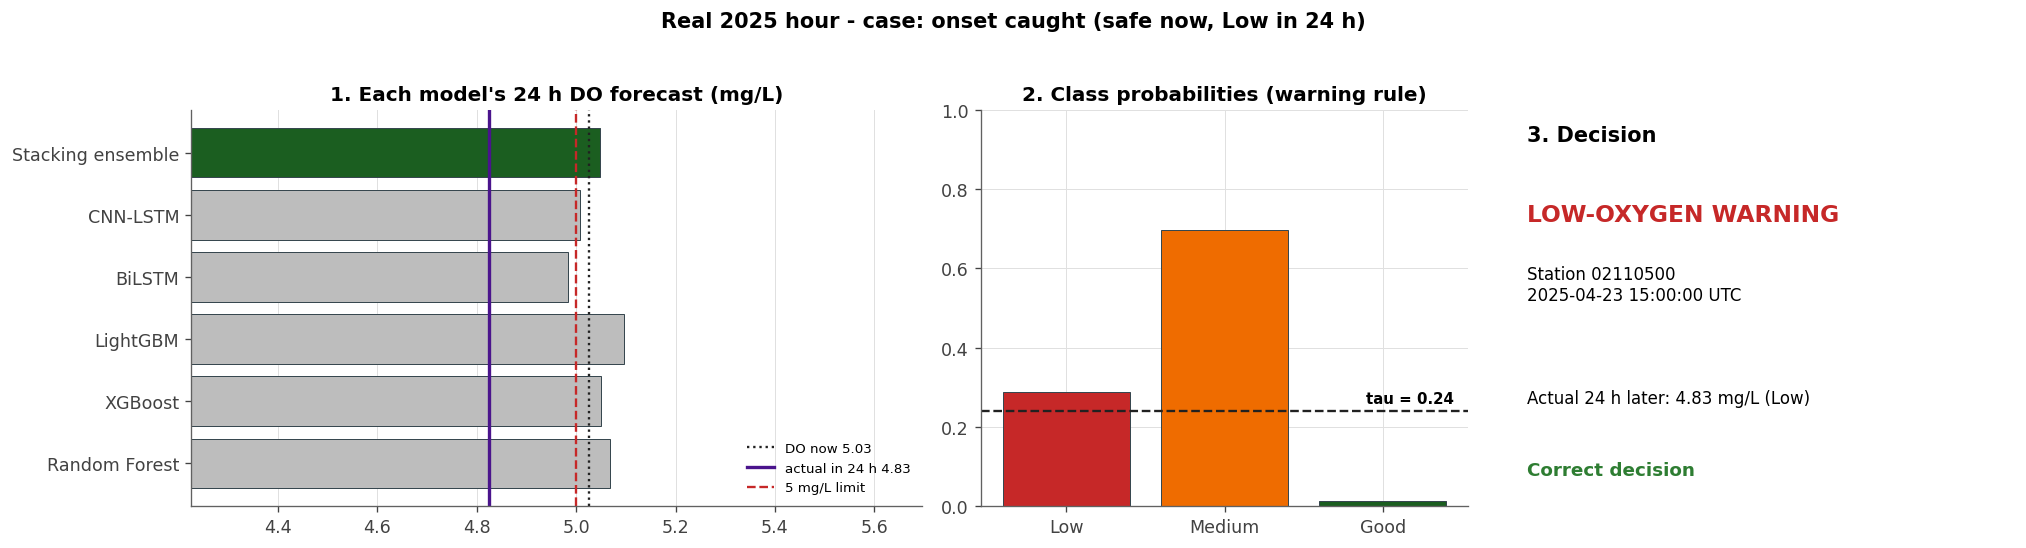

In [17]:
# @title Appendix A. Single-hour prediction card (stacking regression + warning rule)
case = "onset caught (safe now, Low in 24 h)"  # @param ["onset caught (safe now, Low in 24 h)", "healthy river (no warning)", "onset missed (honest failure case)", "false alarm (honest failure case)", "already Low, stays Low"]
CARD = json.loads(EMBEDDED_CARD)
c = next(x for x in CARD["cases"] if x["case"] == case)
tau = CARD["tau_stacking_h24"]
MEMBERS = list(c["members"])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw={"width_ratios": [1.5, 1, 1]})
vals = [c["members"][m] for m in MEMBERS] + [c["stacking_do"]]
names = [NAME[m] for m in MEMBERS] + ["Stacking ensemble"]
axes[0].barh(names, vals, color=[GREY] * len(MEMBERS) + [ACCENT], edgecolor=EDGE, linewidth=0.6)
axes[0].axvline(c["do_now"], color="#212121", ls=":", lw=1.4, label=f"DO now {c['do_now']:.2f}")
axes[0].axvline(c["actual_do"], color="#4A148C", lw=2, label=f"actual in 24 h {c['actual_do']:.2f}")
axes[0].axvline(5, color="#C62828", ls="--", lw=1.4, label="5 mg/L limit")
axes[0].set_xlim(min(vals + [c["actual_do"], 5]) - 0.6, max(vals + [c["actual_do"], c["do_now"]]) + 0.6)
axes[0].set_title("1. Each model's 24 h DO forecast (mg/L)")
axes[0].legend(fontsize=8, loc="lower right")
axes[0].grid(axis="y", visible=False)

p = [c["p_low"], c["p_medium"], c["p_good"]]
axes[1].bar(CLASSES, p, color=["#C62828", "#EF6C00", ACCENT], edgecolor=EDGE, linewidth=0.6)
axes[1].axhline(tau, color="#212121", ls="--", lw=1.4)
axes[1].text(2.45, tau + 0.02, f"tau = {tau:.2f}", ha="right", fontsize=9, fontweight="bold")
axes[1].set_ylim(0, 1)
axes[1].set_title("2. Class probabilities (warning rule)")

axes[2].axis("off")
right = (c["warned"] and c["actual_class"] == 0) or (not c["warned"] and c["actual_class"] != 0)
axes[2].text(0, 0.92, "3. Decision", fontsize=12.5, fontweight="bold")
axes[2].text(0, 0.72, "LOW-OXYGEN WARNING" if c["warned"] else "No warning", fontsize=14, fontweight="bold",
             color="#C62828" if c["warned"] else "#2E7D32")
axes[2].text(0, 0.52, f"Station {c['station']}\n{c['time']} UTC", fontsize=10)
axes[2].text(0, 0.26, f"Actual 24 h later: {c['actual_do']:.2f} mg/L ({CLASSES[c['actual_class']]})",
             fontsize=10)
axes[2].text(0, 0.08, "Correct decision" if right else "Wrong decision (shown for honesty)", fontsize=11,
             fontweight="bold", color="#2E7D32" if right else "#C62828")
fig.suptitle(f"Real 2025 hour - case: {case}", fontsize=12.5, fontweight="bold", y=1.03)
fig.tight_layout()
plt.show()

---

### Provenance

| Item | Source |
|---|---|
| Regression metrics, all methods and horizons | `results/test_v21/metrics_regression_stage2.csv` |
| Classification metrics, all methods, horizons and rules | `results/test_v21/metrics_classification_stage2.csv` |
| Final regression system | `stacking`, Ridge meta-learner fitted on 2024 |
| Final classification system | `ensemble_v21`, weights in `models/ensemble_v21/weights.json` |
| Classification decision rule | `argmax` everywhere except Section 4.3 |
| Figures | `results/notebook_figures/reg_compare_24h.png`, `cls_compare_24h.png`, `cls_confusion_v21.png`, `early_warning_lead_time.png` |
| Training of the members | notebook `02_DO_End_to_End_Training_GPU_Colab.ipynb` |

The previous version of this notebook, including the radar chart, four-panel figure, precision-recall curves,
error-correlation heatmap and the earlier leaderboard built on `results/test/`, is kept unchanged at
`notebooks/archive/01_DO_Algorithm_Comparison_Benchmark_Colab_before_v21.ipynb`.